**Построение прототипа книжного рекомендательного сервиса**

**Цель**: реализовать, проанализировать и сравнить различные подходы рекомендательных систем для сервиса по подбору книг.

Этап 1: знакомство с данными и EDA (Exploratory Data Analysis);

Этап 2: базовые и контентные модели;

Этап 3: коллаборативная фильтрация (Collaborative Filtering — CF);

Этап 4: матричные разложения (Matrix Factorization);

Этап 5: оценка и сравнение моделей;

Этап 6: гибридизация и выводы.

In [1]:
!pip install scikit-surprise -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

RANDOM_STATE = 42

## Этап 1: знакомство с данными и EDA (Exploratory Data Analysis)

In [2]:
ratings = pd.read_csv('data/ratings.csv')
books = pd.read_csv('data/books.csv')
tags = pd.read_csv('data/tags.csv')
book_tags = pd.read_csv('data/book_tags.csv')

Среднее: 3.86
Медиана: 4.0
Доля оценок >=4: 66.2 %


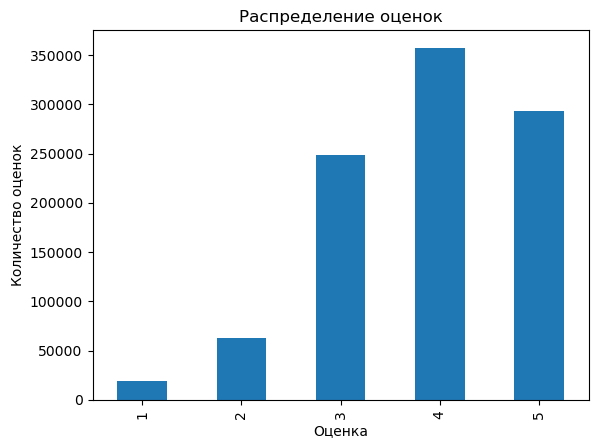

In [3]:
#Распределение оценок
print('Среднее:', round(ratings['rating'].mean(), 2))          
print('Медиана:', ratings['rating'].median())                  
print('Доля оценок >=4:', round((ratings['rating'] >= 4).mean()*100, 1), '%') 

counts = ratings['rating'].value_counts().sort_index()
counts.plot(kind='bar')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.title('Распределение оценок')
plt.show()

В сторону высоких оценок наблюдается явное смещение, количество оценок >= 4 составляеи 66%. 

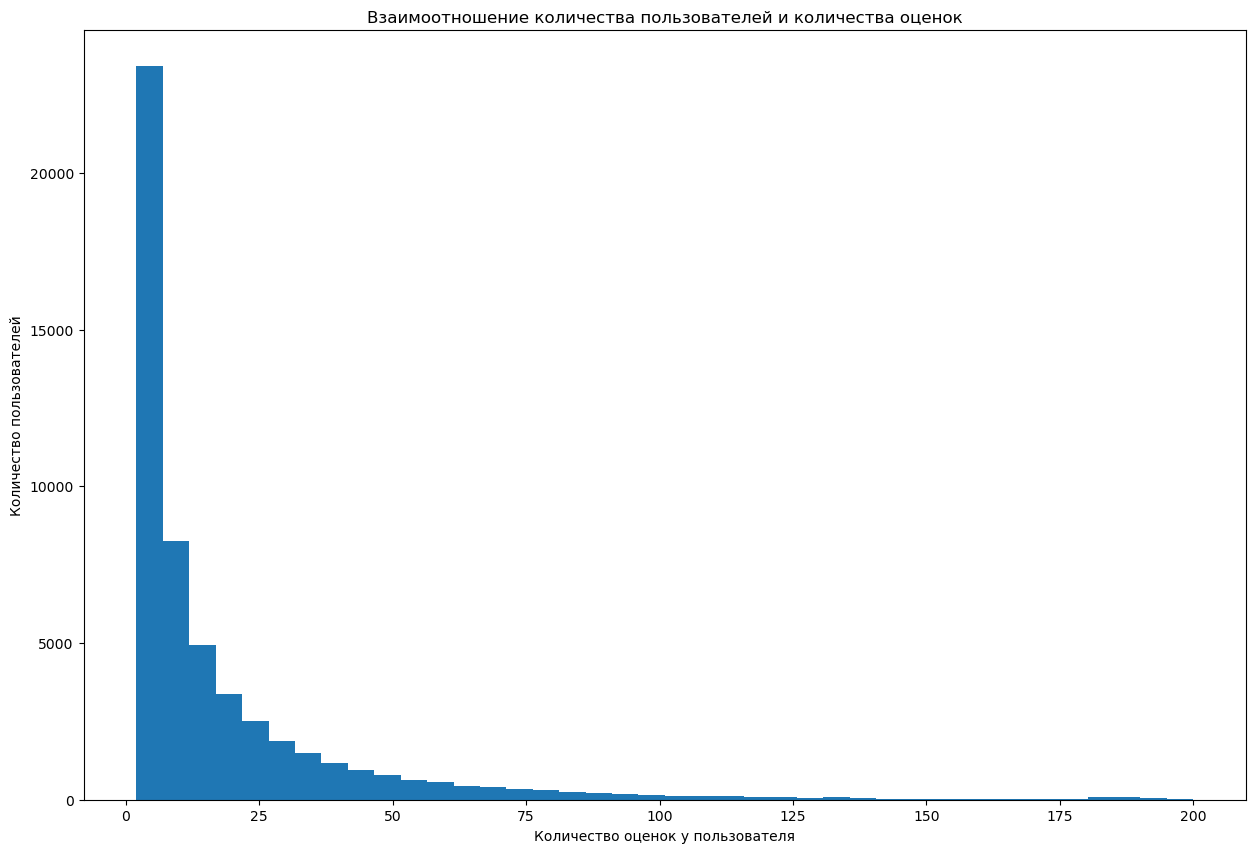

In [4]:
#Aнализ активности пользователей
user_counts = ratings.groupby('user_id').size()
plt.figure(figsize=(15, 10))
plt.hist(user_counts, bins=40)
plt.xlabel('Количество оценок у пользователя')
plt.ylabel('Количество пользователей')
plt.title('Взаимоотношение количества пользователей и количества оценок')
plt.show();

In [5]:
user_counts.describe()

count    53424.000000
mean        18.376685
std         26.268690
min          2.000000
25%          3.000000
50%          8.000000
75%         22.000000
max        200.000000
dtype: float64

25% пользователей имеют всего от 2 до 3 оценок (проблема холодного старта стоит остро). Большинство пользователей имеют до 30 оценок. Также наблюдается группа пользователей с аномально большим количеством оценок (от 175 до 200).

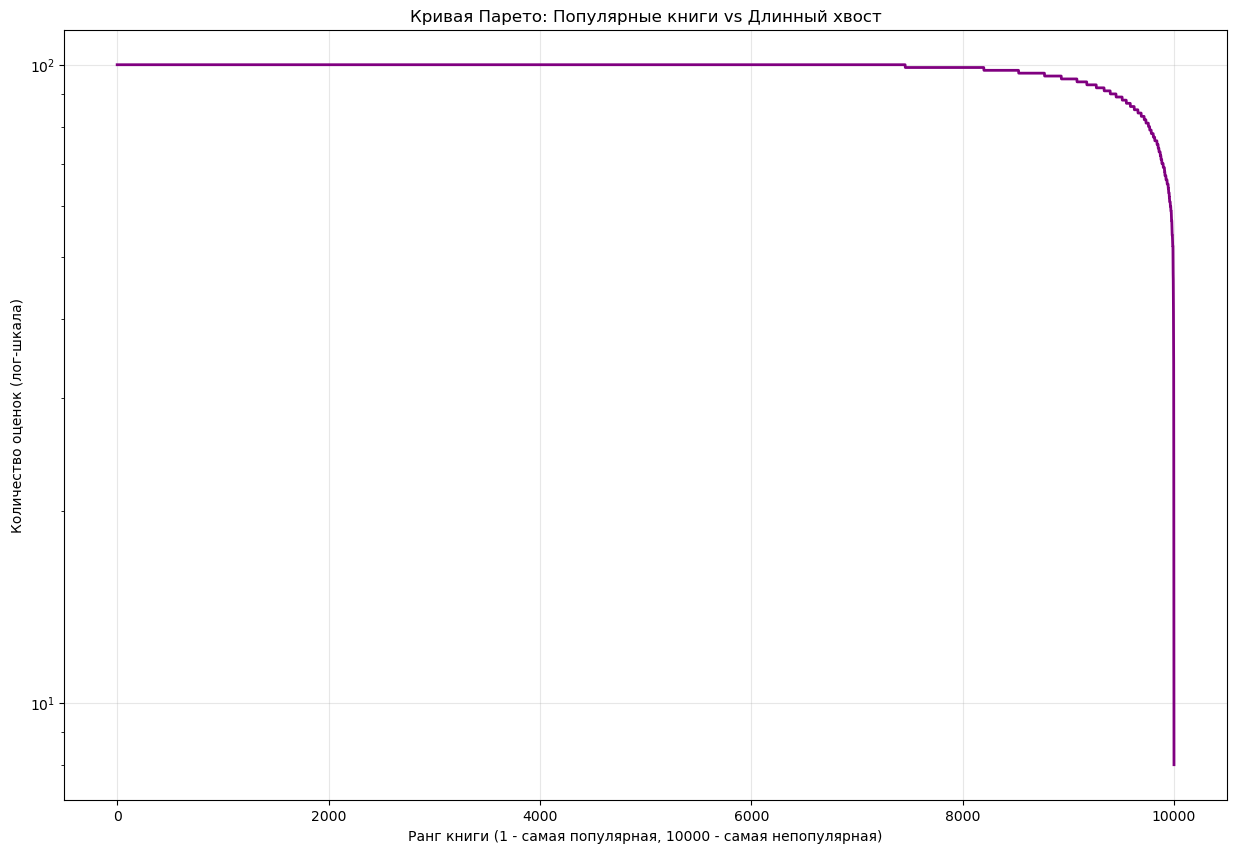

In [6]:
plt.figure(figsize=(15, 10))
sorted_counts = ratings.groupby('book_id').size().sort_values(ascending=False).values

plt.plot(range(len(sorted_counts)), sorted_counts, color='purple', linewidth=2)
plt.yscale('log')
plt.xlabel('Ранг книги (1 - самая популярная, 10000 - самая непопулярная)')
plt.ylabel('Количество оценок (лог-шкала)')
plt.title('Кривая Парето: Популярные книги vs Длинный хвост')
plt.grid(True, alpha=0.3)
plt.show()

Почти все книги имеют ровно 100 оценок, график Парето выглядит как 'полка' затем резко падает вниз. Тем не менее, хвост присутствует.

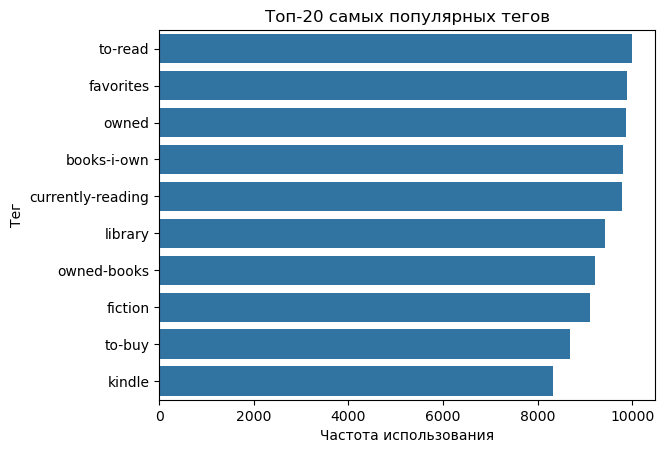

In [7]:
merged_tags = pd.merge(book_tags, tags, on='tag_id')
top_tags = merged_tags['tag_name'].value_counts().head(10)

plt.figure()
sns.barplot(x=top_tags.values, y=top_tags.index)
plt.title('Топ-20 самых популярных тегов')
plt.xlabel('Частота использования')
plt.ylabel('Тег')
plt.show()

Большинство тегов из топа пользовательские, а не жанровые. Если строить контентную модель просто по совпадению тегов, система будет считать похожими книги просто потому, что они обе лежат в чьей-то папке «to-read». Использование TF-IDF здесь будет выгодно, так как этот метод автоматически занизит вес таких частых, но бессмысленных тегов, и повысит значимость редких жанровых маркеров.

В данном наборе данных существует проблшема холодного старта (у 25% пользователей всего от 2 до 3 оценок). Этого объема контекста не хватит для точного поиска похожих профилей в алгоритмах коллаборативной фильтрации. Также присутствует ярко выраженный 'длинный хвост' из непопулярных книг. Модели коллаборативной фильтрации будут склонны рекомендовать всем пользователям одни и те же популярные книги, при этом не рекомендуя нишевую литературу. Данные разрежены - 75% пользователей имеют не более 22 оценок, а книг в датасете тысячи. Доля оценок 4 и 5 составляет 66.2%, а средний балл равен 3.86. Моделям будет легко находить позитивные паттерны, но сложнее выявлять явный негатив.

## Этап 2: базовые и контентные модели

In [8]:
#Алгоритм, возвращающий Top-N самых популярных книг (по среднему рейтингу с порогом минимального количества оценок)
def get_top_popular_books(n=10, min_ratings=50):
    stats = ratings.groupby('book_id')['rating'].agg(['mean', 'count']).reset_index()
    qualified_books = stats[stats['count'] >= min_ratings]
    top = qualified_books.sort_values(by='mean', ascending=False).head(n)
    top_books = top.merge(books[['id', 'title', 'authors']], left_on='book_id', right_on='id', how='left')
    top_books = top_books.drop(columns=['id'])
    return top_books[['book_id', 'title', 'authors', 'mean', 'count']]

In [9]:
top_20 = get_top_popular_books(n=20, min_ratings=50)
display(top_20)

,book_id,title,authors,mean,count
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.820225,89
1,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.780000,100
2,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.780000,100
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.777778,99
4,8946,The Divan,Hafez,4.774194,93
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.770000,100
6,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.770000,100
7,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.750000,100
8,5580,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson,4.750000,100
9,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.750000,100


In [10]:
#Контентная модель
tags_merged =  book_tags.merge(tags, on='tag_id', how='left')
book_tags_agg = tags_merged.groupby('goodreads_book_id')['tag_name'].apply(lambda x: ' '.join(x.astype(str))).reset_index()
books_merged = books.merge(book_tags_agg, left_on='book_id', right_on='goodreads_book_id', how='left')

books_merged['original_title'] = books_merged['original_title'].fillna(books_merged['title'])
books_merged['tag_name'] = books_merged['tag_name'].fillna('')
books_merged['profile'] = books_merged['original_title'] + ' ' + books_merged['tag_name']
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(books_merged['profile'])
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

indices = pd.Series(books_merged.index, index=books_merged['id']).drop_duplicates()

In [11]:
def get_similar_books(book_id, N=5):
    idx = indices[book_id]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:N+1]
    
    book_indices = [i[0] for i in sim_scores]
    result = books_merged[['id', 'title', 'authors']].iloc[book_indices].copy()
    result['similarity_score'] = list(zip(*sim_scores))[1]    
    return result

In [12]:
print('Книга с id=5:')
display(books_merged[books_merged['id'] == 5][['id', 'title', 'authors']])

print('\nПохожие книги:')
display(get_similar_books(book_id=5, N=5))

Книга с id=5:


,id,title,authors
4,5,The Great Gatsby,F. Scott Fitzgerald



Похожие книги:


,id,title,authors,similarity_score
7,8,The Catcher in the Rye,J.D. Salinger,0.824368
31,32,Of Mice and Men,John Steinbeck,0.808015
27,28,Lord of the Flies,William Golding,0.792902
3,4,To Kill a Mockingbird,Harper Lee,0.786107
137,138,The Scarlet Letter,"Nathaniel Hawthorne, Thomas E. Connolly, Nina ...",0.725815


Неперсонализированная модель, которая сортирует по среднему рейтенгу вывела в топ произведения с сильной фанатской базой - издания Гарри Поттера, религиозные тексты. Такую модель можно использовать, как запасной вариант для решения проблемы холодного старта, но ей сильно не хватает персонализации. Контентная модель позволила выбрать наиболее важные жанровые маркеры. Такая модель решает проблему холодного старта для новых книг, модель интерпретируема (понятно, почему рекомендована книга - из-за совпадения ключевых слов). К минусам можно отнести то, что она склонна создавать информационный пузырь, рекомендует только то, что очень похоже на запрошенную книгу, не давая пользователю открыть для себя новые жанры.

## Этап 3: коллаборативная фильтрация (Collaborative Filtering — CF)

In [13]:
#Матрица взаимодействий «пользователь - книга»
ratings_clean = ratings.drop_duplicates(subset=['user_id', 'book_id'], keep='last')
user_item_matrix = ratings_clean.pivot(index='user_id', columns='book_id', values='rating')
print(user_item_matrix.shape)
density = (user_item_matrix.notna().sum().sum() / (user_item_matrix.shape[0] * user_item_matrix.shape[1])) * 100
density

(53424, 10000)


0.18334044624138962

In [14]:
#Item-Based Collaborative Filtering 
matrix_pd = ratings.drop_duplicates(subset=['user_id', 'book_id']).pivot(index='user_id', columns='book_id', values='rating')
user_means = matrix_pd.mean(axis=1)
matrix_centered = matrix_pd.sub(user_means, axis=0).fillna(0)
matrix_sparse = csr_matrix(matrix_centered.values)
item_similarity = cosine_similarity(matrix_sparse.T)
item_similarity_df = pd.DataFrame(item_similarity, index=matrix_pd.columns, columns=matrix_pd.columns)


def predict_rating_item(user_id, book_id, k=10):
    user_ratings = user_item_matrix.loc[user_id].dropna()
    
    if book_id in user_ratings:
        return user_ratings[book_id]
    
    sims = item_similarity_df.loc[book_id, user_ratings.index]
    top_k_sims = sims.sort_values(ascending=False).head(k)
    top_k_sims = top_k_sims[top_k_sims > 0]
    
    if top_k_sims.empty:
        return 'холодный старт'
    
    user_centered_ratings = matrix_centered.loc[user_id]
    prediction = np.dot(top_k_sims, user_centered_ratings[top_k_sims.index]) / top_k_sims.sum()
    
    return user_means[user_id] + prediction

In [15]:
print('Предсказание:', predict_rating_item(user_id=1, book_id=1))

Предсказание: 3.0


К ограничениям данного подхода можно отнести то, что алгоритм не способен рекомендовать новые книги, у которых еще нет оценок (item cold-start), также модель склонна рекомендовать наиболее популярные произведения, так как у них больше всего пересечений с другими книгами. Вычислительная сложность подхода заключается в построении матрицы схожести - время выполнения $O(U\times I^2)$ ($U$ - количество пользователей, $I$ - количество книг). Также для хранения матрицы Item-Item потребуется память $O(I^2)$, если будет миллионы товаров, то оперативная память может закончится. Само предсказание происходит быстро $O(N\log K)$ ($N$ - количество оцененных пользователем книг).

Для больших данных можно выполнить предрасчет и сжатие матрицы. Для каждой книги сохраним только определенный топ соседей, оставшиеся значения занулим. При этом матрица станет более разряженной, что сэкономит память. Кроме этого можно воспользоваться SVD, ALS, что позволит сжать матрицу $U\times I$ в две компактные матрицы эмбеддингов небольшой размерности.

## Этап 4: матричные разложения (Matrix Factorization)

In [16]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings_clean[['user_id', 'book_id', 'rating']], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
svd = SVD(random_state=RANDOM_STATE)
svd.fit(trainset)

predictions = svd.test(testset)
print(f'RMSE на тестовой выборке: {accuracy.rmse(predictions)}')

RMSE: 0.8466
RMSE на тестовой выборке: 0.8466159178467316


In [18]:
train_user_rated_books = trainset.ur

def get_recommendations(user_id, N=5):
    try:
        inner_uid = trainset.to_inner_uid(user_id)
        user_train_ratings = train_user_rated_books[inner_uid]
        rated_in_train = [trainset.to_raw_iid(iid) for iid, _ in user_train_ratings]
    except ValueError:
        rated_in_train = [] 
        
    all_books = ratings_clean['book_id'].unique()
    to_predict = [b for b in all_books if b not in rated_in_train]
    
    pred_ratings = []
    for book_id in to_predict:
        pred = svd.predict(uid=user_id, iid=book_id)
        pred_ratings.append((book_id, pred.est))
        
    pred_ratings.sort(key=lambda x: x[1], reverse=True)
    top = pred_ratings[:N]
    
    top_df = pd.DataFrame(top, columns=['book_id', 'predicted_rating'])
    result = top_df.merge(books[['id', 'title', 'authors']], left_on='book_id', right_on='id', how='left')
    result = result.drop(columns=['id'])
    
    return result

In [19]:
df = pd.DataFrame(testset, columns=['uid', 'iid', 'true_r'])
test_relevant_items = (df[df['true_r'] >= 4].groupby('uid')['iid'].apply(list).to_dict())
get_recommendations(user_id=5, N=10)

,book_id,predicted_rating,title,authors
0,3628,5.000000,The Complete Calvin and Hobbes,Bill Watterson
1,5207,4.982725,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
2,862,4.949654,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson
3,6590,4.931369,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
4,4344,4.926596,The Day the Crayons Quit,"Drew Daywalt, Oliver Jeffers"
5,8982,4.926176,"Fables, Vol. 10: The Good Prince","Bill Willingham, Mark Buckingham, Steve Leialo..."
6,3753,4.887330,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling
7,6902,4.886230,Standing for Something: 10 Neglected Virtues T...,Gordon B. Hinckley
8,9842,4.881274,Humans of New York: Stories,Brandon Stanton
9,8109,4.866419,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, ..."


SVD показал точность 0.84, в отличие от простых методов, он улавливает скрытые связи между пользователями и книгами. Алгоритм успешно сжимает матрицу с плотностью 0.18% в две плотные матрицы эмбеддингов небольшой размерности. 

## Этап 5: оценка и сравнение моделей

In [20]:
np.random.seed(42)
eval_users = np.random.choice(list(test_relevant_items.keys()), size=1000, replace=False)

In [21]:
def calculate_metrics(recommended_list, relevant_list, k=10):
    top_k = recommended_list[:k]
    hits = len(set(top_k) & set(relevant_list))
    
    precision = hits / k
    
    recall = hits / len(relevant_list)
    
    dcg = 0.0
    for i, item in enumerate(top_k):
        if item in relevant_list:
            dcg += 1 / np.log2(i + 2)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(k, len(relevant_list))))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    
    return precision, recall, ndcg

In [22]:
K = 10
results = []

popular_books = top_20['book_id'].tolist()[:K]
p_metrics = np.array([calculate_metrics(popular_books, test_relevant_items[u], K) for u in eval_users])

results.append({
    'Model': 'Popularity',
    'Precision@10': p_metrics[:, 0].mean(),
    'Recall@10': p_metrics[:, 1].mean(),
    'nDCG@10': p_metrics[:, 2].mean()
})

svd_metrics = []
for u in eval_users:
    recs_df = get_recommendations(u, N=K)
    svd_books = recs_df['book_id'].tolist()
    svd_metrics.append(calculate_metrics(svd_books, test_relevant_items[u], K))
    
svd_metrics = np.array(svd_metrics)

results.append({
    'Model': 'SVD',
    'Precision@10': svd_metrics[:, 0].mean(),
    'Recall@10': svd_metrics[:, 1].mean(),
    'nDCG@10': svd_metrics[:, 2].mean()
})

In [24]:
def get_recommendations_item_based(user_id, N=10):
    all_books = matrix_pd.columns
    try:
        inner_uid = trainset.to_inner_uid(user_id)
        user_train_ratings = trainset.ur[inner_uid]
        rated_in_train = [trainset.to_raw_iid(iid) for iid, _ in user_train_ratings]
    except ValueError:
        rated_in_train = []
        
    unrated_books = [b for b in all_books if b not in rated_in_train]
    
    preds = []
    for book_id in unrated_books:
        pred = predict_rating_item(user_id, book_id, k=10)
        if pred != 'холодный старт':
            preds.append((book_id, pred))
            
    preds.sort(key=lambda x: x[1], reverse=True)
    return [p[0] for p in preds[:N]]

In [25]:
item_metrics = []
for u in eval_users:
    item_books = get_recommendations_item_based(u, N=K)
    item_metrics.append(calculate_metrics(item_books, test_relevant_items[u], K))

item_metrics = np.array(item_metrics)

results.append({
    'Model': 'Item-Based CF',
    'Precision@10': item_metrics[:, 0].mean(),
    'Recall@10': item_metrics[:, 1].mean(),
    'nDCG@10': item_metrics[:, 2].mean()
})

In [26]:
metrics_df = pd.DataFrame(results).set_index('Model')
display(metrics_df)

,Precision@10,Recall@10,nDCG@10
Model,,,
Popularity,0.0006,0.001077,0.000824
SVD,0.0009,0.001268,0.001063
Item-Based CF,0.0266,0.035180,0.040765


Оценка моделей была выполнена на выборке из 1000 пользователей из-за вычислительной сложности Item-Based CF. Лучший результат оказался у Item-Based CF. SVD имеет низкую ошибку предсказания (rmse=0.84), однако в задаче топ-n рекомендаций уступает так как склонна завышать оценки глобальным хитам, при этом вытесняются релевантные для пользователя объекты. Модель Popularity показвыет худшие результаты, топ бестселлеров активные пользователи уже прочитали на этапе обучения.

## Этап 6: гибридизация и выводы

Для борьбы с холодным стартом можно рассмотреть следующий гибридный подход:

1. Для новых пользователей без истории оценок применить модель Popularity (также можно использовать топ книг по выбранным при регистрации жанрам).
2. Для новых книг, у которых еще нет достаточного количества оценок для матрицы коллаборативной фильтрации использовать модель Content-Based.
3. Для активных пользователей, о которых уже достаточно информации применить Item-Based CF или SVD. Для максимизации качества предсказания объединить их линейной комбинацией.

Выводы по работе:

Наилучшие качество показала Item-Based CF. Данный алгоритм прямого поиска соседей лучще улавливает локальные связи, что дало преимущество в метриках ранжирования перед глобальными латентными факторами SVD.

Для Popularity к сильным сторонам можно отнести, что вычисления происходят почти мгновенно, она страхует систему при отсутствии данных, но полностью лишена персонализации.

Content-Based позволяет решить проблему новых товаров и не зависит от разреженности матрицы, но ограничена качеством и зашумленностью пользовательских тегов.

Item-Based CF предоставляет релевантные и интерпретируемые предсказания, однако требует $O(I^2)$ памяти и вычислений, также плохо масштабируется на большое количество товаров.

SVD хорошо справляется с разреженностью, масштабируется, минимизирует rmse, но уязвим к холодному старту.


Для дальнейшего улучшения системы можно воспользоваться современными NLP-модели (Word2Vec, BERT) для создания плотных семантических векторов на основе полных описаний и рецензий. Воспользоватся нейросетевыми архитектурами для захвата нелинейных взаимодействий между профилем читателя и признаками книги.